<a href="https://colab.research.google.com/github/Vishnu372608/solar-power-using-ann--aidl/blob/main/Another_copy_of_AIDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load both datasets


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load CSV files
generation = pd.read_csv("Plant_1_Generation_Data.csv")
weather = pd.read_csv("Plant_1_Weather_Sensor_Data.csv")

# Display dataset dimensions
print("Generation dataset shape:", generation.shape)
print("Weather dataset shape:", weather.shape)

# Display column names
print("\nGeneration columns:")
print(generation.columns.tolist())

print("\nWeather columns:")
print(weather.columns.tolist())

# Display first five rows
print("\nGeneration data:")
display(generation.head())

print("\nWeather data:")
display(weather.head())

Generation dataset shape: (68778, 7)
Weather dataset shape: (3182, 6)

Generation columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

Weather columns:
['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']

Generation data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0



Weather data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


Check data quality

In [ ]:
print("GENERATION DATA")
print("Missing values:", generation.isnull().sum().sum())
print("Duplicate rows:", generation.duplicated().sum())

print("\nWEATHER DATA")
print("Missing values:", weather.isnull().sum().sum())
print("Duplicate rows:", weather.duplicated().sum())

print("\nGeneration data types:")
print(generation.dtypes)

print("\nWeather data types:")
print(weather.dtypes)

GENERATION DATA
Missing values: 0
Duplicate rows: 0

WEATHER DATA
Missing values: 0
Duplicate rows: 0

Generation data types:
DATE_TIME       object
PLANT_ID         int64
SOURCE_KEY      object
DC_POWER       float64
AC_POWER       float64
DAILY_YIELD    float64
TOTAL_YIELD    float64
dtype: object

Weather data types:
DATE_TIME               object
PLANT_ID                 int64
SOURCE_KEY              object
AMBIENT_TEMPERATURE    float64
MODULE_TEMPERATURE     float64
IRRADIATION            float64
dtype: object


Clean and combine the datasets

In [ ]:
# Work on copies of the original datasets
gen = generation.copy()
wth = weather.copy()

# Convert timestamps
gen["DATE_TIME"] = pd.to_datetime(
    gen["DATE_TIME"], errors="coerce", dayfirst=True
)

wth["DATE_TIME"] = pd.to_datetime(
    wth["DATE_TIME"], errors="coerce", dayfirst=True
)

# Remove invalid timestamps
gen = gen.dropna(subset=["DATE_TIME"])
wth = wth.dropna(subset=["DATE_TIME"])

# Aggregate inverter power at each timestamp
generation_agg = (
    gen.groupby("DATE_TIME", as_index=False)
       .agg(
           AC_POWER=("AC_POWER", "sum"),
           DC_POWER=("DC_POWER", "sum")
       )
)

# Aggregate weather measurements at each timestamp
weather_agg = (
    wth.groupby("DATE_TIME", as_index=False)
       .agg(
           AMBIENT_TEMPERATURE=("AMBIENT_TEMPERATURE", "mean"),
           MODULE_TEMPERATURE=("MODULE_TEMPERATURE", "mean"),
           IRRADIATION=("IRRADIATION", "mean")
       )
)

# Merge both datasets
combined_df = pd.merge(
    generation_agg,
    weather_agg,
    on="DATE_TIME",
    how="inner",
    validate="one_to_one"
)

# Sort and clean numeric values
combined_df = combined_df.sort_values("DATE_TIME")
combined_df = combined_df.replace([np.inf, -np.inf], np.nan)

required_columns = [
    "AC_POWER",
    "DC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

combined_df = combined_df.dropna(
    subset=required_columns
).reset_index(drop=True)

print("Combined dataset shape:", combined_df.shape)
print("\nMissing values:")
print(combined_df.isnull().sum())

display(combined_df.head())

Combined dataset shape: (3157, 6)

Missing values:
DATE_TIME              0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64


/tmp/ipykernel_569/1092153033.py:10: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  wth["DATE_TIME"] = pd.to_datetime(


,DATE_TIME,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,0.0,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,0.0,0.0,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,0.0,0.0,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,0.0,0.0,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,0.0,0.0,24.621525,22.165423,0.0


Save the cleaned dataset

In [ ]:
combined_df.to_csv(
    "Solar_Combined_Dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


Analyze and visualize the dataset

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check the cleaned dataset
print("Dataset shape:", combined_df.shape)
display(combined_df.head())

# Summary statistics
display(combined_df.describe())

Dataset shape: (3157, 6)


,DATE_TIME,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,0.0,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,0.0,0.0,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,0.0,0.0,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,0.0,0.0,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,0.0,0.0,24.621525,22.165423,0.0


,DATE_TIME,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,3157,3157.000000,3157.000000,3157.000000,3157.000000,3157.000000
mean,2020-06-01 06:41:41.298701568,6704.830534,68560.019625,25.560257,31.175453,0.230103
min,2020-05-15 00:00:00,0.000000,0.000000,20.398505,18.140415,0.000000
25%,2020-05-23 23:15:00,0.000000,0.000000,22.739895,21.130249,0.000000
50%,2020-06-01 12:30:00,814.880357,8430.196429,24.680324,24.801971,0.027748
75%,2020-06-09 18:00:00,13752.112500,140409.892856,27.941221,41.449481,0.451576
max,2020-06-17 23:45:00,29150.212499,298937.785710,35.252486,65.545714,1.221652
std,NaN,8604.217954,88055.843520,3.351059,12.272685,0.301348


Solar power generation over time

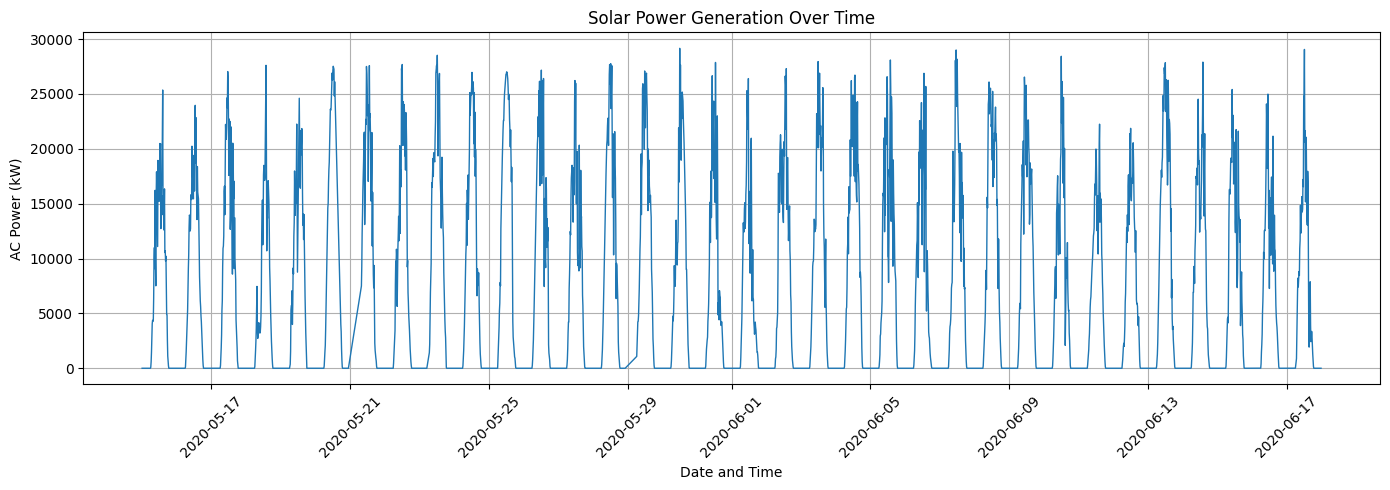

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    combined_df["DATE_TIME"],
    combined_df["AC_POWER"],
    linewidth=1
)

plt.title("Solar Power Generation Over Time")
plt.xlabel("Date and Time")
plt.ylabel("AC Power (kW)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Irradiation versus solar power

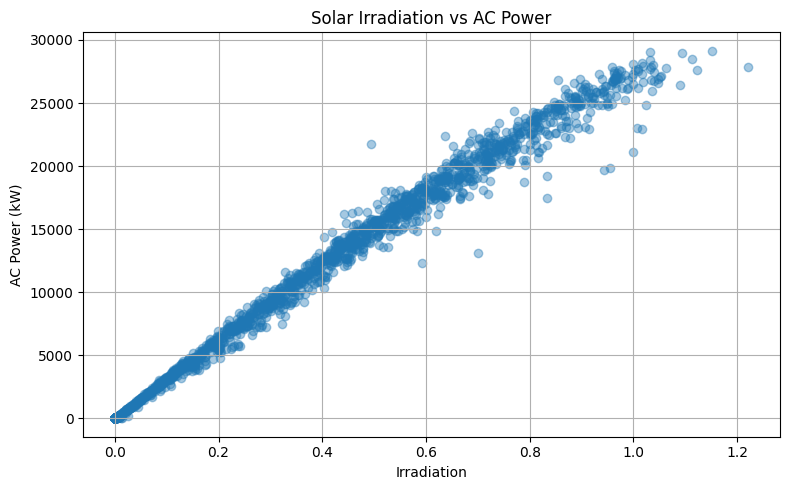

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    combined_df["IRRADIATION"],
    combined_df["AC_POWER"],
    alpha=0.4
)

plt.title("Solar Irradiation vs AC Power")
plt.xlabel("Irradiation")
plt.ylabel("AC Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

Correlation heatmap

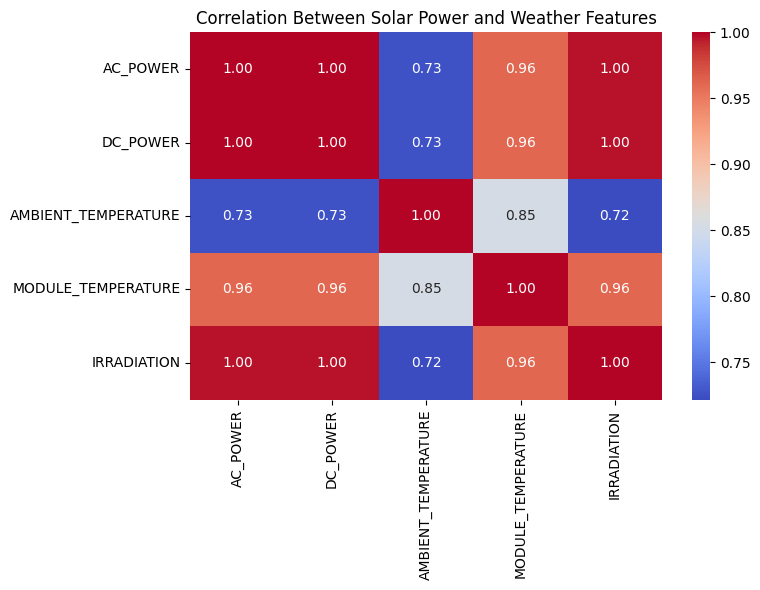

In [ ]:
numeric_cols = [
    "AC_POWER",
    "DC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    combined_df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Solar Power and Weather Features")
plt.tight_layout()
plt.show()

Prepare input features for the ANN

In [ ]:
# Create a copy for feature engineering
model_df = combined_df.copy()

# Extract time features
model_df["HOUR"] = model_df["DATE_TIME"].dt.hour
model_df["DAY_OF_YEAR"] = model_df["DATE_TIME"].dt.dayofyear

# Encode time of day cyclically
import numpy as np

model_df["HOUR_SIN"] = np.sin(
    2 * np.pi * model_df["HOUR"] / 24
)

model_df["HOUR_COS"] = np.cos(
    2 * np.pi * model_df["HOUR"] / 24
)

# Define input features
features = [
    "IRRADIATION",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "HOUR_SIN",
    "HOUR_COS",
    "DAY_OF_YEAR"
]

# Define target
target = "AC_POWER"

X = model_df[features].astype("float32")
y = model_df[target].astype("float32")

print("Input shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Input shape: (3157, 6)
Target shape: (3157,)


,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,HOUR_SIN,HOUR_COS,DAY_OF_YEAR
0,0.0,25.184317,22.857508,0.000000,1.000000,136.0
1,0.0,25.084589,22.761667,0.000000,1.000000,136.0
2,0.0,24.935753,22.592306,0.000000,1.000000,136.0
3,0.0,24.846130,22.360851,0.000000,1.000000,136.0
4,0.0,24.621525,22.165422,0.258819,0.965926,136.0


,AC_POWER
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0


Split the dataset into training and testing sets

In [ ]:
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Training period:",
    model_df["DATE_TIME"].iloc[0],
    "to",
    model_df["DATE_TIME"].iloc[split_index - 1]
)

print(
    "Testing period:",
    model_df["DATE_TIME"].iloc[split_index],
    "to",
    model_df["DATE_TIME"].iloc[-1]
)

Training samples: 2525
Testing samples: 632
Training period: 2020-05-15 00:00:00 to 2020-06-11 09:15:00
Testing period: 2020-06-11 09:30:00 to 2020-06-17 23:45:00


Normalize the input features

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature normalization completed.")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature normalization completed.
Scaled training shape: (2525, 6)
Scaled testing shape: (632, 6)


In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("TensorFlow imported successfully!")

TensorFlow version: 2.21.0
TensorFlow imported successfully!


In [ ]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,561 (10.00 KB)

 Trainable params: 2,561 (10.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("ANN training completed successfully!")

Epoch 1/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 124854320.0000 - mae: 6882.9580 - val_loss: 115385152.0000 - val_mae: 6519.8931
Epoch 2/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 124785608.0000 - mae: 6881.6357 - val_loss: 115274944.0000 - val_mae: 6517.6792
Epoch 3/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 124512800.0000 - mae: 6875.0103 - val_loss: 114895752.0000 - val_mae: 6508.3384
Epoch 4/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 123747720.0000 - mae: 6854.7661 - val_loss: 113988296.0000 - val_mae: 6484.2666
Epoch 5/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 122167248.0000 - mae: 6811.2954 - val_loss: 112323400.0000 - val_mae: 6438.4033
Epoch 6/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 119458776.0000 - mae: 6734.6768 - val_loss: 109672920.0000 - val_mae: 6364.0859
Epoch 7/100
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 115353424.0000 - mae: 6615.9390 - val_loss: 105851680.0000 - val_mae: 6255.7329
Epoch 8/100
64/64 ━━━━━━━

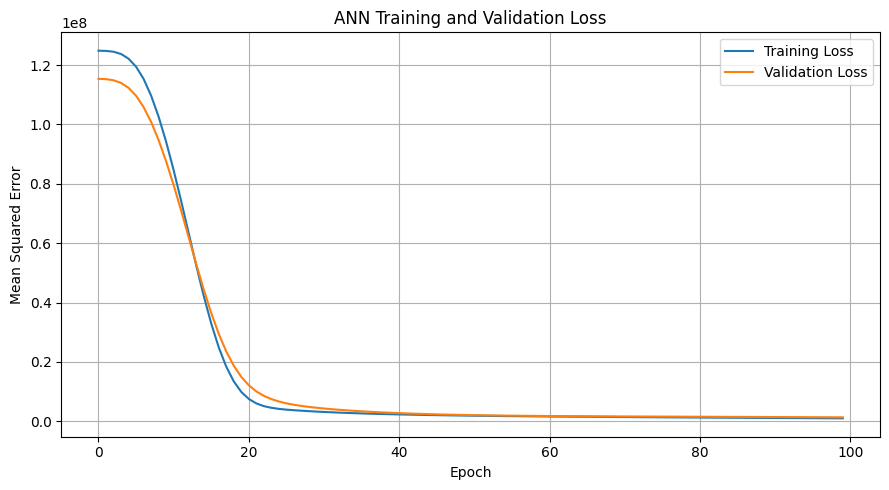

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test_scaled, verbose=0).ravel()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("SOLAR POWER PREDICTION RESULTS")
print("------------------------------")
print(f"MAE  : {mae:.3f} kW")
print(f"MSE  : {mse:.3f} (kW)^2")
print(f"RMSE : {rmse:.3f} kW")
print(f"R²   : {r2:.3f}")

SOLAR POWER PREDICTION RESULTS
------------------------------
MAE  : 533.253 kW
MSE  : 816369.188 (kW)^2
RMSE : 903.532 kW
R²   : 0.987


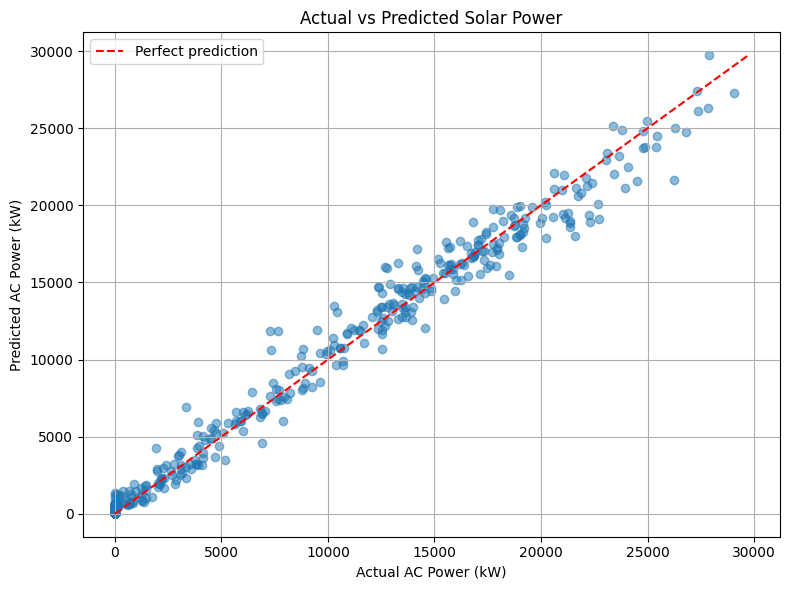

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

low = min(float(y_test.min()), float(y_pred.min()))
high = max(float(y_test.max()), float(y_pred.max()))

plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Actual AC Power (kW)")
plt.ylabel("Predicted AC Power (kW)")
plt.title("Actual vs Predicted Solar Power")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Save the trained ANN model
model.save("solar_ann_model.keras")

# Save the feature scaler
joblib.dump(scaler, "solar_input_scaler.pkl")

# Save the feature names in the correct order
joblib.dump(features, "solar_features.pkl")

print("ANN model saved successfully!")
print("Scaler saved successfully!")
print("Feature list saved successfully!")

ANN model saved successfully!
Scaler saved successfully!
Feature list saved successfully!


In [ ]:
import os
import zipfile
from google.colab import files

# Ensure the cleaned dataset exists
if 'combined_df' in globals():
    combined_df.to_csv("Solar_Combined_Dataset.csv", index=False)
    print("Ensured Solar_Combined_Dataset.csv is saved.")

# List of files to download
files_to_zip = [
    "solar_ann_model.keras",
    "solar_input_scaler.pkl",
    "solar_features.pkl",
    "Solar_Combined_Dataset.csv"
]

# Create a zip file containing all of them
zip_filename = "solar_model_and_data.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
        else:
            print(f"Warning: {file} not found, skipping.")

print(f"Created {zip_filename} containing your model and data files.")

# Trigger a single download
files.download(zip_filename)

Ensured Solar_Combined_Dataset.csv is saved.
Created solar_model_and_data.zip containing your model and data files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
pip install streamlit tensorflow numpy scikit-learn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 27.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 56.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
%%writefile app.py
import streamlit as st
import numpy as np
import joblib
import tensorflow as tf

st.set_page_config(
    page_title="Solar Power Prediction",
    page_icon="☀️"
)

@st.cache_resource
def load_files():
    model = tf.keras.models.load_model("solar_ann_model.keras")
    scaler = joblib.load("solar_input_scaler.pkl")
    features = joblib.load("solar_features.pkl")
    return model, scaler, features

model, scaler, features = load_files()

st.title("☀️ Solar Power Generation Prediction")
st.write("Artificial Neural Network (ANN)")

irradiation = st.number_input(
    "Solar irradiation", min_value=0.0, value=0.5
)
ambient_temp = st.number_input(
    "Ambient temperature (°C)", value=25.0
)
module_temp = st.number_input(
    "Module temperature (°C)", value=30.0
)
hour = st.slider("Hour of day", 0, 23, 12)
day_of_year = st.slider("Day of year", 1, 366, 180)

if st.button("Predict Solar Power"):
    values = {
        "IRRADIATION": irradiation,
        "AMBIENT_TEMPERATURE": ambient_temp,
        "MODULE_TEMPERATURE": module_temp,
        "HOUR_SIN": np.sin(2 * np.pi * hour / 24),
        "HOUR_COS": np.cos(2 * np.pi * hour / 24),
        "DAY_OF_YEAR": day_of_year
    }

    X_input = np.array(
        [[values[f] for f in features]],
        dtype=np.float32
    )

    prediction = model.predict(
        scaler.transform(X_input), verbose=0
    )[0, 0]

    st.metric("Predicted AC Power", f"{max(0, float(prediction)):.2f} kW")
    st.caption("Estimated output based on the trained historical-data model.")

Overwriting app.py


In [ ]:
import os

for filename in [
    "app.py",
    "solar_ann_model.keras",
    "solar_input_scaler.pkl",
    "solar_features.pkl"
]:
    print(filename, "FOUND" if os.path.exists(filename) else "MISSING")

app.py FOUND
solar_ann_model.keras FOUND
solar_input_scaler.pkl FOUND
solar_features.pkl FOUND


In [ ]:
!streamlit run app.py --server.port 8501 --server.headless true &>/content/streamlit.log &

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴
added 22 packages in 7s
⠴
⠴3 packages are looking for funding
⠴  run `npm fund` for details
⠴

In [ ]:
!ps aux | grep streamlit
!tail -n 50 /content/streamlit.log


root        3217 33.9  0.5 456132 76796 ?        Sl   08:08   0:03 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501 --server.headless true
root        3289  0.0  0.0   7344  3620 ?        S    08:08   0:00 /bin/bash -c ps aux | grep streamlit
root        3291  0.0  0.0   6548  2300 ?        S    08:08   0:00 grep streamlit


2026-11-20 08:08:47.720 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.70.235.13:8501



In [ ]:
!streamlit run /content/app.py \
  --server.address 0.0.0.0 \
  --server.port 8501 \
  --server.headless true \
  > /content/streamlit.log 2>&1 &

In [ ]:
!curl -I http://127.0.0.1:8501
!tail -n 30 /content/streamlit.log

HTTP/1.1 200 OK
date: Fri, 20 Nov 2026 08:08:53 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Fri, 20 Nov 2026 08:08:33 GMT
etag: "bc47b0fe0638a0bc7f5cbd858126a783"
cache-control: no-cache



In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O /content/cloudflared.deb

!apt-get install -y /content/cloudflared.deb

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Note, selecting 'cloudflared' instead of '/content/cloudflared.deb'
The following NEW packages will be installed:
  cloudflared
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 0 B/20.0 MB of archives.
After this operation, 40.3 MB of additional disk space will be used.
Get:1 /content/cloudflared.deb cloudflared amd64 2026.11.1 [20.0 MB]
Selecting previously unselected package cloudflared.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack /content/cloudflared.deb ...
Unpacking cloudflared (2026.11.1) ...
Setting up cloudflared (2026.11.1) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared --version

cloudflared version 2026.11.1 (built 2026-11-17-15:04 UTC)


In [ ]:
import subprocess
import time

log = open("/content/streamlit_final.log", "w")

process = subprocess.Popen(
    [
        "python", "-m", "streamlit", "run",
        "/content/app.py",
        "--server.address=0.0.0.0",
        "--server.port=8501",
        "--server.headless=true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    stdin=subprocess.DEVNULL,
    start_new_session=True
)

time.sleep(5)

print("Streamlit process ID:", process.pid)
print("Process status:", process.poll())

Streamlit process ID: 3972
Process status: 1


In [ ]:
!curl -I --connect-timeout 5 --max-time 10 http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Fri, 20 Nov 2026 08:09:29 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Fri, 20 Nov 2026 08:08:33 GMT
etag: "bc47b0fe0638a0bc7f5cbd858126a783"
cache-control: no-cache



In [ ]:
!cloudflared tunnel --url http://127.0.0.1:8501

2026-11-20T08:09:31Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-20T08:09:31Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-20T08:09:34Z INF +--------------------------------------------------------------------------------------------+
2026-11-20T08:09:34Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-20T08:09:34Z INF |  https://february-weddings-idol-eclipse.trycloudflare.